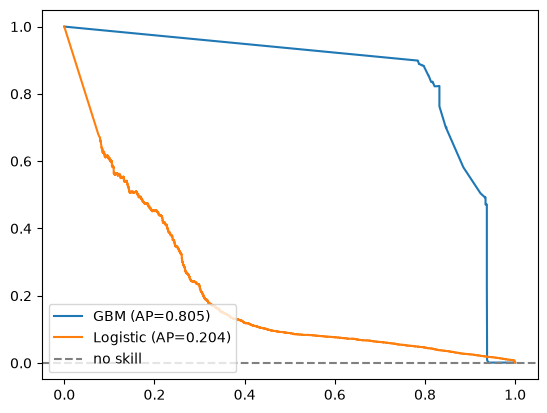

[[1588238     364]
 [    367    1686]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000   1588602
           1      0.822     0.821     0.822      2053

    accuracy                          1.000   1590655
   macro avg      0.911     0.911     0.911   1590655
weighted avg      1.000     1.000     1.000   1590655

cost-optimal threshold: 0.066


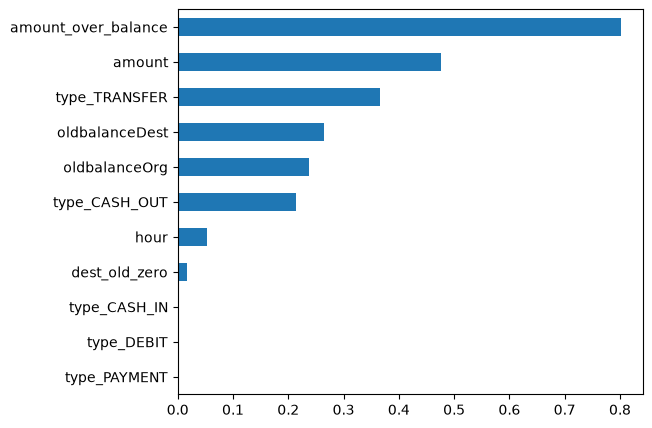

In [ ]:
import pandas as pd, numpy as np, joblib, json, matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance

meta = json.load(open("../models/model_meta.json"))
gb = joblib.load("../models/gbm_fraud.joblib")
lg = joblib.load("../models/logit_baseline.joblib")
te = pd.read_csv("../Data/processed/test_set.csv")
y_te = te.pop("isFraud"); X_te = te[meta["features"]].astype("float32")
p_gb = gb.predict_proba(X_te)[:, 1]; p_lg = lg.predict_proba(X_te)[:, 1]

# 1. PR curves
for name, p in [("GBM", p_gb), ("Logistic", p_lg)]:
    pr, rc, _ = precision_recall_curve(y_te, p)
    plt.plot(rc, pr, label=f"{name} (AP={average_precision_score(y_te, p):.3f})")
plt.axhline(y_te.mean(), ls="--", c="grey", label="no skill")
plt.legend(loc="lower left")
plt.savefig("../results/figures/pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# 2. Confusion matrix at the chosen threshold
pred = (p_gb >= meta["threshold"]).astype(int)
print(confusion_matrix(y_te, pred)); print(classification_report(y_te, pred, digits=3))

# 3. Cost view (review_cost is your assumption: cost of checking one flagged transaction)
review_cost = 5_000   # same currency units as `amount`; adjust to something defensible
amt = X_te["amount"].values
ths = np.linspace(0.05, 0.99, 60)
cost = [amt[(p_gb < t) & (y_te.values == 1)].sum() + review_cost * (p_gb >= t).sum() for t in ths]
print("cost-optimal threshold:", round(ths[int(np.argmin(cost))], 3))

# 4. Feature importance (sampled for speed)
idx = np.random.RandomState(0).choice(len(X_te), 200_000, replace=False)
r = permutation_importance(gb, X_te.iloc[idx], y_te.iloc[idx],
                           scoring="average_precision", n_repeats=3, random_state=0)
pd.Series(r.importances_mean, index=X_te.columns).sort_values().plot.barh(figsize=(6, 5))
plt.savefig("../results/figures/importance.png", dpi=150, bbox_inches="tight"); plt.show()